In [1]:

# 1. ZIP dosyasını aç
!unzip -o /content/TinyLM_Dataset_Starter.zip -d /content/

# 2. Proje klasörüne geç
%cd /content/TinyLM_Dataset_Starter

# 3. Dosyaları kontrol et
!ls -lah

# 4. Gerekli kütüphaneleri yükle
!pip install -q -r requirements.txt

# 5. TinyStories veri kümesini hazırla
!python prepare_tinystories.py --out tinylm_data


Archive:  /content/TinyLM_Dataset_Starter.zip
   creating: /content/TinyLM_Dataset_Starter/
  inflating: /content/TinyLM_Dataset_Starter/README.md  
  inflating: /content/TinyLM_Dataset_Starter/prepare_tinystories.py  
 extracting: /content/TinyLM_Dataset_Starter/requirements.txt  
/content/TinyLM_Dataset_Starter
total 28K
drwxr-xr-x 2 root root 4.0K Nov 14 19:05 .
drwxr-xr-x 1 root root 4.0K Nov 15 08:03 ..
-rw-r--r-- 1 root root  11K Nov 14 19:04 prepare_tinystories.py
-rw-r--r-- 1 root root 3.9K Nov 14 19:04 README.md
-rw-r--r-- 1 root root   46 Nov 14 19:04 requirements.txt
Source: roneneldan/TinyStories @ f54c09fd23315a6f9c86f9dc80f725de7d8f9c64
README.md: 100% 1.06k/1.06k [00:00<00:00, 854kB/s]
Selected 10000 distinct train stories; scanned 10047 rows.
Selected 500 distinct validation stories; scanned 500 rows.

DATA PREPARATION COMPLETE
Output: /content/TinyLM_Dataset_Starter/tinylm_data
training_story_count: 10000
validation_story_count: 500
shared_vocab_size: 92
actual_substit

cihaz: cpu | n_embd 128, n_head 4 (head_size 32), n_layer 4, block_size 64, dropout 0.1, batch 32, lr 0.001, 4000 adım
eğitim: 9,232,834 karakter (iki koşulda aynı uzunluk) | validation: 412,539 karakter | sözlük: 92 karakter
gürültü: 1,048,719 karakter değişti (harflerin %15.00 kadarı, tüm karakterlerin %11.36 kadarı)
kaynak: roneneldan/TinyStories @ f54c09fd2331 | train_clean.txt sha256 38d3bcfeba42
not: validation'da olup eğitim metninde hiç geçmeyen karakterler: ['±', 'Ã'] (10 konum)

--- Model A_clean ---  823,644 parametre (0.82 M)
step     0: train 4.7071 | val 4.7041 (6.787 bpc)  (0.5 dk)
step   500: train 1.6547 | val 1.6299 (2.352 bpc)  (4.5 dk, kalan ~31 dk)
step  1000: train 1.4105 | val 1.3839 (1.997 bpc)  (8.4 dk, kalan ~25 dk)
step  1500: train 1.3121 | val 1.2861 (1.855 bpc)  (12.3 dk, kalan ~20 dk)
step  2000: train 1.2439 | val 1.2150 (1.753 bpc)  (16.1 dk, kalan ~16 dk)
step  2500: train 1.2062 | val 1.1839 (1.708 bpc)  (20.0 dk, kalan ~12 dk)
step  3000: train 1.176

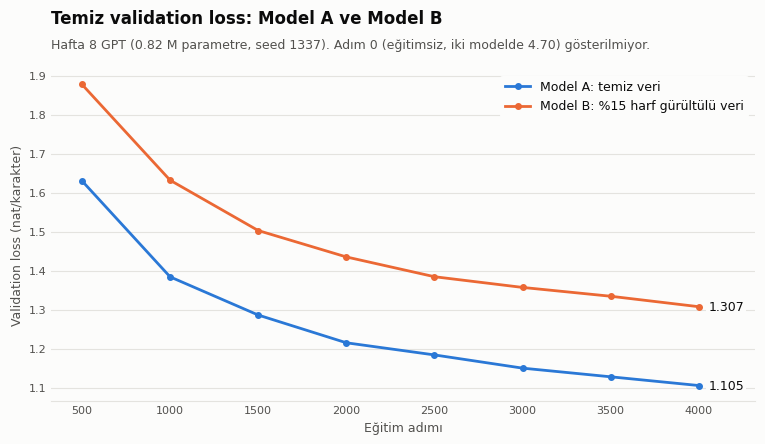

kaydedildi: sonuclar/val_loss_karsilastirma.png
=== ÜRETİLEN METİNDE GEÇERLİ KELİME ORANI (temiz eğitim metninde geçen kelimeler) ===
Model A: %90.4 | Model B: %51.3  (2000 karakterlik örnek)
referans, temiz validation metni: %99.7 | referans, gürültülü eğitim metni: %58.2

==================== MODEL A (temiz veriyle eğitildi) ====================
--- boş bağlamdan, ilk 500 karakter ---
Then, she wouldn't get the waited the ime brave with the there was a broquith big putuble cake ut.

Lily and Mom and Daddy went better and Lily patents. She came until through the train and had curious. Lily was ruined to help them to take the air sun outside. The boy went to get outside, but it the birdceled and laughing.

After the see and the voice. She ajnot But she reached as the forest of the garden. They did not like to prinches, but she would never daying a learn.

But who was scovered t

--- "Once upon a time" ile başlayarak ---
Once upon a time, in a rabon. Walked in his him from it me. Maybe 

# Tartışma: bulgular ve sınırlılıklar

## Bulgular

- **Hipotez destekleniyor.** 4000 adım sonunda temiz validation loss, temiz veriyle eğitilen Model A'da 1.1055, gürültülü veriyle eğitilen Model B'de 1.3075 nat/karakter. Fark +0.2020 nat (+0.291 bit/karakter); perplexity 3.02 → 3.70.
- **Eğitim boyunca:** adım 0 dışındaki 8 ölçüm noktasının 8 tanesinde Model B'nin loss'u daha yüksek. Fark ilk ölçüm noktasında (adım 500) +0.2472, son ölçüm noktasında (adım 4000) +0.2020 nat.
- **Fark nerede:** harf pozisyonlarında +0.2510, diğer pozisyonlarda (boşluk, noktalama, rakam) +0.0452 nat (validation karakterlerinde harf payı: %76.2).
- **Doğruluk:** sonraki karakteri doğru tahmin etme oranı Model A'da %65.56, Model B'de %62.08 (-3.48 puan).
- **Üretilen metin:** aynı seed ile üretilen 2000 karakterlik örnekte temiz eğitim metninde geçen kelimelerin oranı Model A'da %90.4, Model B'de %51.3 (temiz validation metninde %99.7, gürültülü eğitim metninde %58.2).
- **Eğitim süresi:** Model A 27.1 dk, Model B 27.5 dk (406 ve 412 ms/adım, cpu). İki model aynı boyutta aynı hesabı yaptığı için gürültünün süreye etkisi beklenmez; aradaki fark makinenin o anki yükünü yansıtır.

## Yorum

- Model B, hedefleri de gürültülü olan metinde eğitildi. Bu yüzden harf pozisyonlarında olasılığın bir kısmını "rastgele başka bir harf" ihtimaline ayırmayı öğrenir. Dili Model A kadar iyi bilse bile bu temkinin temiz metindeki bedeli harf pozisyonu başına en fazla −ln(1 − 0.15) = 0.163 nat olur.
- Ölçülen harf farkı (0.251 nat) bu sınırı 0.088 nat aşıyor. Yani farkın tamamı temkinli tahminle açıklanamaz: Model B bu adım bütçesinde temiz metni tahmin etmeyi de daha kötü öğrenmiş.
- Temkinli tahmin harflerin kendi aralarındaki sıralamasını değiştirmez, bu yüzden doğruluğu çok az etkiler. Doğruluktaki 3.48 puanlık fark, Model B'nin en olası karakteri de daha seyrek bildiğini gösterir.
- Harf olmayan pozisyonlarda hedef hiç bozulmadı, yine de Model B orada +0.0452 nat daha kötü. Bu fark hedef gürültüsünden gelemez; gürültülü bağlamdan öğrenmenin doğrudan maliyetidir.
- Model B'nin ürettiği metindeki geçerli kelime oranı (%51.3), kendi gürültülü eğitim metnindeki orana (%58.2) yakın: model yalnızca dili değil, eğitim verisindeki gürültüyü de öğrenmiş ve üretirken tekrarlıyor.

## Sınırlılıklar

- **Tek seed (1337).** Koşul başına bir model eğitildi; seed'den seed'e değişim ölçülmedi, bu yüzden farkın belirsizliği bilinmiyor.
- **Tek gürültü türü, tek oran.** Yalnızca ASCII harflerin %15 kadarının aynı büyük/küçük harf sınıfından rastgele bir harfle değiştirilmesi denendi (tüm karakterlerin %11.4 kadarı). Silme, ekleme, kelime düzeyinde hatalar ve başka oranlar denenmedi; sonuç "veri kalitesi"nin geneline taşınamaz.
- **Sabit adım bütçesi.** 4000 adımdaki fark, "daha kötü bir son nokta" ile "daha yavaş öğrenme"yi ayırt etmez. Son ölçüm aralığında (adım 3500 → 4000) val loss Model A'da -0.0224, Model B'de -0.0268 nat değişti.
- **Örneklem.** 10,000 eğitim hikâyesi veri setinin tamamından tekdüze çekilmedi (akışın baş kısmından, karıştırma tamponuyla). Yalnızca birebir aynı hikâyeler elendi; benzer hikâyeler eğitim ve validation'da birlikte bulunabilir.
- **Yalnızca temiz validation.** Gürültülü girdiye dayanıklılık ölçülmedi; Model B o koşulda farklı davranabilir.
- **Ölçü.** Loss, örtüşmeyen 64 karakterlik parçalarda ölçüldü; her parçanın ilk karakterleri kısa bağlamla tahmin edilir. Farklı block_size ile alınan sonuçlar (CPU ve GPU ayarı) birbiriyle doğrudan karşılaştırılamaz.
- **Metin kalitesi.** Model başına tek örnek ve basit bir kelime oranı kullanıldı; anlam ve tutarlılık ölçülmedi.
- **Süre.** Tek ölçüm, paylaşımlı bir makinede; donanıma bağlıdır.
- **Görülmemiş karakterler.** Validation'da eğitim metninde hiç geçmeyen 2 karakter var (10 konum); iki modeli de aynı şekilde etkiler.


sonuclar/ klasörü:
  deney_sonuclari.json                 0.02 MB
  model_A_clean.pt                     3.60 MB
  model_B_noisy.pt                     3.60 MB
  ornek_metinler.txt                   0.00 MB
  sonuc_A_clean.json                   0.01 MB
  sonuc_B_noisy.json                   0.01 MB
  tartisma.md                          0.00 MB
  val_loss_karsilastirma.png           0.11 MB

zip: /content/TinyLM_Dataset_Starter/TinyLM_Week8_Baseline_sonuclar.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
"""TinyLM Research — Week 8 Baseline Experiment (tek dosya).

Hafta 8 GPT'si (Görev 3) iki kez eğitilir: Model A temiz hikâyelerle, Model B harflerinin %15'i bozulmuş
hikâyelerle. İki model de aynı temiz validation setinde ölçülür. Mimari, başlangıç ağırlıkları, tokenizer,
batch boyutu, öğrenme oranı, optimizer, adım sayısı ve minibatch pozisyonları iki modelde aynıdır.

Colab'da kullanım (veri hazırlama hücresi çalıştıktan sonra, yani /content/TinyLM_Dataset_Starter içindeyken):
    1) Bu dosyayı Colab'a yükle, sonra yeni bir kod hücresinde:   %run /content/tinylm_week8_deney.py
    2) ya da dosyanın tamamını yeni bir kod hücresine yapıştırıp çalıştır.
    Hücre dışında `python tinylm_week8_deney.py` olarak da çalışır; o zaman grafik ekrana değil dosyaya yazılır.

Çıktılar sonuclar/ klasörüne yazılır: model_A_clean.pt, model_B_noisy.pt, val_loss_karsilastirma.png,
ornek_metinler.txt, deney_sonuclari.json, tartisma.md. Hepsi TinyLM_Week8_Baseline_sonuclar.zip içinde toplanır.

Bölüm numaraları notebook ile aynıdır; 1. bölüm (veri hazırlığı) Colab'daki ilk hücredir.
"""


# %% 2. Konfigürasyon
# Hiperparametreler Hafta 8 Görev 3'teki iki ayardır (GPU varsa videodaki konfig, yoksa CPU konfigi). Tek fark:
# protokol gereği iki ayarda da 4.000 adım.
#
# GPU ile çalıştırmak için: Çalışma zamanı > Çalışma zamanı türünü değiştir > T4 GPU. Çalışma zamanı değişince
# /content sıfırlanır; zip'i yeniden yükleyip 1. hücreden başla.

import hashlib
import json
import math
import os
import platform
import re
import shutil
import string
import time

import torch
import torch.nn as nn
from torch.nn import functional as F

SEED = 1337                   # Hafta 8 ile aynı seed; iki model de bununla başlar
VERI = 'tinylm_data'          # 1. hücrenin ürettiği klasör
CIKTI = 'sonuclar'            # checkpoint, grafik, JSON ve örnek metinler buraya yazılır
YENIDEN_EGIT = False          # True: kayıtlı sonuç olsa bile modelleri baştan eğit
try:                          # hücrede / %run ile mi çalışıyor (grafik ve metin ekranda gösterilir), yoksa `python dosya.py` mi?
    NOTEBOOK = hasattr(get_ipython(), 'kernel')
except NameError:
    NOTEBOOK = False

# --- donanıma göre konfigürasyon (Hafta 8 Görev 3'teki iki ayar) ---
device = 'cuda' if torch.cuda.is_available() else 'cpu'
if device == 'cuda':   # GPU (örn. Colab T4): videodaki konfig
    n_embd, n_head, n_layer, block_size, batch_size = 384, 6, 6, 256, 64
    dropout, learning_rate = 0.2, 3e-4
else:                  # CPU (Colab CPU, 2 çekirdek)
    n_embd, n_head, n_layer, block_size, batch_size = 128, 4, 4, 64, 32
    dropout, learning_rate = 0.1, 1e-3
max_iters = 4000       # protokol: iki model de 4.000 adım
eval_interval = 500    # sabit ölçüm noktaları: 0, 500, ..., 4000
TRAIN_OLCUM = 100_000  # train loss, eğitim metninin ilk 100.000 karakterinde izlenir

KONFIG = dict(seed=SEED, n_embd=n_embd, n_head=n_head, n_layer=n_layer, block_size=block_size,
              batch_size=batch_size, dropout=dropout, learning_rate=learning_rate, max_iters=max_iters,
              eval_interval=eval_interval, train_olcum=TRAIN_OLCUM, optimizer='AdamW (PyTorch varsayılanları)',
              tokenizer='karakter düzeyi, ortak sözlük', device=device)
print(f'cihaz: {device} | n_embd {n_embd}, n_head {n_head} (head_size {n_embd // n_head}), n_layer {n_layer}, '
      f'block_size {block_size}, dropout {dropout}, batch {batch_size}, lr {learning_rate}, {max_iters} adım')


# %% 3. Veri ve ortak tokenizer
# İki model de aynı karakter sözlüğünü (shared_char_vocab.json) kullanır. Minibatch pozisyonları burada bir kez
# üretilir; temiz ve gürültülü eğitim metinleri aynı uzunlukta ve hizalı olduğu için iki model her adımda metnin
# aynı yerlerini görür, tek fark o yerlerdeki bozulmuş harflerdir.

def sha256(yol):
    h = hashlib.sha256()
    with open(yol, 'rb') as f:
        for parca in iter(lambda: f.read(1 << 20), b''):
            h.update(parca)
    return h.hexdigest()


def oku(ad):
    with open(os.path.join(VERI, ad), 'r', encoding='utf-8') as f:
        return f.read()


assert os.path.isdir(VERI), (f'{VERI}/ klasörü bulunamadı: önce veri hazırlama hücresini çalıştır '
                             f'(çalışma klasörü /content/TinyLM_Dataset_Starter olmalı)')

# --- dosyalar, hazırlama raporundaki dosyalarla aynı mı? ---
rapor = json.loads(oku('dataset_report.json'))
DOSYALAR = ['train_clean.txt', 'train_noisy.txt', 'validation_clean.txt', 'shared_char_vocab.json']
veri_hash = {ad: sha256(os.path.join(VERI, ad)) for ad in DOSYALAR}
for ad in DOSYALAR:
    assert veri_hash[ad] == rapor['file_sha256'][ad], f'{ad} hazırlandıktan sonra değişmiş'

# --- ortak tokenizer (Hafta 8'deki encode/decode; sözlük dosyadan gelir) ---
chars = json.loads(oku('shared_char_vocab.json'))['chars']
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join(itos[i] for i in l)

clean_text, noisy_text, val_text = oku('train_clean.txt'), oku('train_noisy.txt'), oku('validation_clean.txt')
assert set(clean_text) | set(noisy_text) | set(val_text) <= set(chars), 'sözlükte olmayan karakter var'
assert len(clean_text) == len(noisy_text), 'temiz ve gürültülü eğitim metni aynı uzunlukta olmalı'

train_clean = torch.tensor(encode(clean_text), dtype=torch.long)
train_noisy = torch.tensor(encode(noisy_text), dtype=torch.long)
val_data = torch.tensor(encode(val_text), dtype=torch.long)

# --- minibatch pozisyonları: bir kez üretilir, iki model de aynı adımda aynı pozisyonları görür ---
POZISYONLAR = torch.randint(len(train_clean) - block_size, (max_iters, batch_size),
                            generator=torch.Generator().manual_seed(SEED))
POZISYON_SHA256 = hashlib.sha256(POZISYONLAR.numpy().tobytes()).hexdigest()

HARF_MI = torch.tensor([c in string.ascii_letters for c in chars])     # hangi token'lar ASCII harf
degisen = (train_clean != train_noisy).sum().item()
harf = HARF_MI[train_clean].sum().item()
gorulmemis = sorted(set(val_text) - set(clean_text))

print(f'eğitim: {len(train_clean):,} karakter (iki koşulda aynı uzunluk) | validation: {len(val_data):,} karakter | '
      f'sözlük: {vocab_size} karakter')
print(f'gürültü: {degisen:,} karakter değişti (harflerin %{100 * degisen / harf:.2f} kadarı, '
      f'tüm karakterlerin %{100 * degisen / len(train_clean):.2f} kadarı)')
print(f'kaynak: {rapor["source_dataset"]} @ {rapor["revision"][:12]} | train_clean.txt sha256 {veri_hash["train_clean.txt"][:12]}')
if gorulmemis:
    print(f'not: validation\'da olup eğitim metninde hiç geçmeyen karakterler: {gorulmemis} '
          f'({sum(val_text.count(c) for c in gorulmemis)} konum)')


# %% 4. Model: Hafta 8 GPT
# Sınıflar Hafta 8 notebook'undaki (Görev 3) kodun kendisidir; hiçbir satırı değiştirilmedi. Model A ve Model B bu
# sınıftan, aynı seed ile kurulur.

# --- model: Hafta 8 Görev 3'teki GPT (kod olduğu gibi alındı) ---
class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k, q = self.key(x), self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = self.dropout(F.softmax(wei, dim=-1))
        return wei @ self.value(x)


class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.dropout(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))


class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.ReLU(), nn.Linear(4 * n_embd, n_embd),
                                 nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.sa = MultiHeadAttention(n_head, n_embd // n_head)
        self.ffwd = FeedForward()
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        return x + self.ffwd(self.ln2(x))


class GPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.token_embedding_table(idx) + self.position_embedding_table(torch.arange(T, device=idx.device))
        logits = self.lm_head(self.ln_f(self.blocks(x)))
        loss = None if targets is None else F.cross_entropy(logits.view(B * T, -1), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -block_size:])
            probs = F.softmax(logits[:, -1, :], dim=-1)
            idx = torch.cat((idx, torch.multinomial(probs, num_samples=1)), dim=1)
        return idx


# %% 5. Batch ve ölçüm
# tam_olcum, Hafta 8'deki kesin ölçüdür (tam_val_loss): metnin tamamı, örtüşmeyen block_size'lık parçalar,
# rastgelelik yok. İki model de validation setinin birebir aynı pozisyonlarında ölçülür. Loss'a ek olarak
# doğruluğu ve loss'un harf / harf olmayan pozisyonlardaki payını da döndürür.

def get_batch(d, ix):
    # Hafta 8'deki get_batch; tek fark: pozisyonlar (ix) dışarıdan gelir, böylece iki modelde aynıdır
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)


@torch.no_grad()
def tam_olcum(model, d):
    """Metnin tamamı, örtüşmeyen block_size'lık chunk'lar (Hafta 8'deki kesin ölçü)."""
    model.eval()                                   # eval(): dropout kapalı
    n_chunks = (len(d) - 1) // block_size
    x = d[:n_chunks * block_size].view(n_chunks, block_size)
    y = d[1:n_chunks * block_size + 1].view(n_chunks, block_size)
    harf_mi = HARF_MI.to(device)
    toplam = harf_toplam = 0.0
    dogru = harf_sayi = 0
    for i in range(0, n_chunks, 256):
        logits, _ = model(x[i:i + 256].to(device))
        logits, yb = logits.reshape(-1, vocab_size), y[i:i + 256].reshape(-1).to(device)
        l = F.cross_entropy(logits, yb, reduction='none')
        h = harf_mi[yb]                            # hedef karakter ASCII harf mi?
        toplam += l.sum().item()
        harf_toplam += l[h].sum().item()
        harf_sayi += h.sum().item()
        dogru += (logits.argmax(-1) == yb).sum().item()
    model.train()
    n = y.numel()
    return {'loss': toplam / n, 'acc': dogru / n, 'loss_harf': harf_toplam / harf_sayi,
            'loss_diger': (toplam - harf_toplam) / (n - harf_sayi), 'harf_orani': harf_sayi / n, 'n': n}


# %% 6. Eğitim
# Döngü Hafta 8'deki ile aynıdır: AdamW, sabit öğrenme oranı, her adımda bir minibatch. Ölçüm noktalarında (0,
# 500, ..., 4000) temiz validation setinin tamamı ölçülür. Bitmiş bir modelin checkpoint'i ve sonucu sonuclar/
# klasöründe durduğu sürece hücre yeniden çalıştırıldığında o model tekrar eğitilmez.
#
# train sütunu, modelin kendi eğitim metninin ilk 100.000 karakterinde ölçülür. Model B için bu metin
# gürültülüdür; gürültü tahmin edilemediği için train değerinin temiz validation loss'undan yüksek çıkması
# beklenir.

def simdi():
    if device == 'cuda':
        torch.cuda.synchronize()                   # GPU'daki iş bitmeden süre okunmasın
    return time.time()


def agirlik_sha256(model):
    # ağırlıkların parmak izi: başlangıçta iki modelde aynı çıkmalı
    h = hashlib.sha256()
    for ad, p in sorted(model.state_dict().items()):
        h.update(ad.encode())
        h.update(p.detach().cpu().numpy().tobytes())
    return h.hexdigest()


def kos(ad, train_data):
    ckpt_yolu, sonuc_yolu = f'{CIKTI}/model_{ad}.pt', f'{CIKTI}/sonuc_{ad}.json'
    torch.manual_seed(SEED)                        # aynı seed -> iki modelde aynı başlangıç ağırlıkları ve dropout maskeleri
    model = GPT().to(device)

    if not YENIDEN_EGIT and os.path.exists(ckpt_yolu) and os.path.exists(sonuc_yolu):
        with open(sonuc_yolu, encoding='utf-8') as f:
            sonuc = json.load(f)
        if sonuc['konfig'] == KONFIG and sonuc['veri_sha256'] == veri_hash:
            model.load_state_dict(torch.load(ckpt_yolu, map_location=device)['model'])
            print(f'\n--- Model {ad}: kayıtlı sonuç bulundu, yeniden eğitilmedi (val loss {sonuc["val"]["loss"]:.4f}) ---')
            return model, sonuc

    n_params = sum(p.numel() for p in model.parameters())
    print(f'\n--- Model {ad} ---  {n_params:,} parametre ({n_params / 1e6:.2f} M)')
    baslangic = agirlik_sha256(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)   # Hafta 8 ile aynı
    train_olcum = train_data[:TRAIN_OLCUM]
    gecmis, olcum_sn = [], 0.0
    t_bas = simdi()
    for it in range(max_iters + 1):
        if it % eval_interval == 0 or it == max_iters:
            t0 = simdi()
            v, t = tam_olcum(model, val_data), tam_olcum(model, train_olcum)
            olcum_sn += simdi() - t0
            gecmis.append({'step': it, 'val': v, 'train': t})
            kalan = f', kalan ~{(max_iters - it) * (simdi() - t_bas) / it / 60:.0f} dk' if 0 < it < max_iters else ''
            print(f'step {it:5d}: train {t["loss"]:.4f} | val {v["loss"]:.4f} ({v["loss"] / math.log(2):.3f} bpc)  '
                  f'({(simdi() - t_bas) / 60:.1f} dk{kalan})')
        if it == max_iters:
            break
        xb, yb = get_batch(train_data, POZISYONLAR[it])
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    toplam_sn = simdi() - t_bas

    torch.save({'model': model.state_dict(), 'konfig': KONFIG, 'chars': chars}, ckpt_yolu)
    sonuc = {'model': ad, 'konfig': KONFIG, 'veri_sha256': veri_hash, 'n_params': n_params,
             'baslangic_sha256': baslangic, 'pozisyon_sha256': POZISYON_SHA256,
             'val': gecmis[-1]['val'], 'train': gecmis[-1]['train'], 'gecmis': gecmis,
             'egitim_sn': toplam_sn - olcum_sn, 'olcum_sn': olcum_sn, 'toplam_sn': toplam_sn,
             'ms_adim': 1000 * (toplam_sn - olcum_sn) / max_iters}
    with open(sonuc_yolu, 'w', encoding='utf-8') as f:
        json.dump(sonuc, f, ensure_ascii=False, indent=2)
    print(f'eğitim süresi: {sonuc["egitim_sn"] / 60:.1f} dk ({sonuc["ms_adim"]:.0f} ms/adım, {device}) '
          f'+ ölçümler {olcum_sn / 60:.1f} dk | kaydedildi: {ckpt_yolu}')
    return model, sonuc


os.makedirs(CIKTI, exist_ok=True)
model_A, sonuc_A = kos('A_clean', train_clean)     # Model A: temiz hikâyeler
model_B, sonuc_B = kos('B_noisy', train_noisy)     # Model B: %15 harf gürültülü hikâyeler


# %% 7. Sonuç tablosu ve deney konfigürasyonu

A, B = sonuc_A, sonuc_B

# --- kontrollü değişkenler gerçekten aynı mıydı? ---
assert A['konfig'] == B['konfig'] and A['veri_sha256'] == B['veri_sha256'], 'konfigürasyon ya da veri farklı'
assert A['baslangic_sha256'] == B['baslangic_sha256'], 'başlangıç ağırlıkları farklı'
assert A['pozisyon_sha256'] == B['pozisyon_sha256'], 'minibatch pozisyonları farklı'
assert abs(A['gecmis'][0]['val']['loss'] - B['gecmis'][0]['val']['loss']) < 1e-4, 'adım 0 val loss farklı'
print('kontrol: iki model aynı başlangıç ağırlıkları, aynı minibatch pozisyonları, aynı konfigürasyon ve '
      'aynı veri dosyalarıyla eğitildi; adım 0 val loss iki modelde aynı.')

ln2 = math.log(2)
satirlar = [
    ('val loss (nat/karakter)', A['val']['loss'], B['val']['loss'], '.4f'),
    ('bit/karakter (bpc)', A['val']['loss'] / ln2, B['val']['loss'] / ln2, '.4f'),
    ('perplexity', math.exp(A['val']['loss']), math.exp(B['val']['loss']), '.3f'),
    ('sonraki karakter doğruluğu (%)', 100 * A['val']['acc'], 100 * B['val']['acc'], '.2f'),
    ('val loss, harf pozisyonları', A['val']['loss_harf'], B['val']['loss_harf'], '.4f'),
    ('val loss, diğer pozisyonlar', A['val']['loss_diger'], B['val']['loss_diger'], '.4f'),
    ('train loss (kendi eğitim metni)', A['train']['loss'], B['train']['loss'], '.4f'),
    ('eğitim süresi (dk)', A['egitim_sn'] / 60, B['egitim_sn'] / 60, '.1f'),
    ('ms/adım', A['ms_adim'], B['ms_adim'], '.0f'),
]
print(f'\n=== SONUÇ: {max_iters} adım sonunda, temiz validation setinin tamamı ({A["val"]["n"]:,} karakter) ===')
print(f'{"":<32} {"Model A (temiz)":>16} {"Model B (gürültülü)":>20} {"fark (B − A)":>13}')
for ad, a, b, bicim in satirlar:
    print(f'{ad:<32} {a:>16{bicim}} {b:>20{bicim}} {b - a:>+13{bicim}}')

print('\n=== ÖLÇÜM NOKTALARI: temiz val loss ===')
print(f'{"adım":>6} {"Model A":>9} {"Model B":>9} {"fark":>9}')
for ga, gb in zip(A['gecmis'], B['gecmis']):
    print(f'{ga["step"]:>6} {ga["val"]["loss"]:>9.4f} {gb["val"]["loss"]:>9.4f} {gb["val"]["loss"] - ga["val"]["loss"]:>+9.4f}')

# --- deney konfigürasyonu + sonuçlar tek dosyada ---
ozet = {
    'deney': 'TinyLM Research — Week 8 Baseline Experiment',
    'konfig': KONFIG,
    'veri': {'kaynak': rapor['source_dataset'], 'revizyon': rapor['revision'],
             'egitim_hikaye': rapor['training_story_count'], 'validation_hikaye': rapor['validation_story_count'],
             'egitim_karakter': len(train_clean), 'validation_karakter': len(val_data), 'vocab_size': vocab_size,
             'degisen_karakter': degisen, 'harflerin_orani': degisen / harf, 'tum_karakterlerin_orani': degisen / len(train_clean),
             'sha256': veri_hash},
    'ortam': {'torch': torch.__version__, 'python': platform.python_version(), 'cpu_cekirdek': os.cpu_count(),
              'cihaz': torch.cuda.get_device_name(0) if device == 'cuda' else 'cpu'},
    'model_A': A, 'model_B': B,
}
with open(f'{CIKTI}/deney_sonuclari.json', 'w', encoding='utf-8') as f:
    json.dump(ozet, f, ensure_ascii=False, indent=2)
print(f'\nkaydedildi: {CIKTI}/deney_sonuclari.json')


# %% 8. Validation loss karşılaştırma grafiği

import matplotlib
if not NOTEBOOK:
    matplotlib.use('Agg')                          # ekran yok: yalnızca dosyaya çiz
import matplotlib.pyplot as plt

zemin, murekkep, soluk, izgara = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
seriler = [('Model A: temiz veri', A, '#2a78d6'), ('Model B: %15 harf gürültülü veri', B, '#eb6834')]

fig, ax = plt.subplots(figsize=(8, 4.6), facecolor=zemin)
ax.set_facecolor(zemin)
for ad, s, renk in seriler:
    nokta = [(g['step'], g['val']['loss']) for g in s['gecmis'] if g['step'] > 0]
    xs, ys = [p[0] for p in nokta], [p[1] for p in nokta]
    ax.plot(xs, ys, color=renk, linewidth=2, marker='o', markersize=4, label=ad)
    ax.annotate(f'{ys[-1]:.3f}', (xs[-1], ys[-1]), xytext=(7, 0), textcoords='offset points', va='center',
                color=murekkep, fontsize=9, bbox=dict(facecolor=zemin, edgecolor='none', pad=1.5))
ax.set_xlabel('Eğitim adımı', color=soluk, fontsize=9)
ax.set_ylabel('Validation loss (nat/karakter)', color=soluk, fontsize=9)
ax.set_xticks([g['step'] for g in A['gecmis'] if g['step'] > 0])
ax.set_xlim(right=max_iters * 1.08)
ax.grid(axis='y', color=izgara, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=soluk, labelsize=8, length=0)
for kenar in ('top', 'right', 'left'):
    ax.spines[kenar].set_visible(False)
ax.spines['bottom'].set_color(izgara)
ax.legend(frameon=True, facecolor=zemin, edgecolor='none', framealpha=1, fontsize=9, labelcolor=murekkep,
          loc='upper right')
fig.subplots_adjust(left=0.09, right=0.97, top=0.84, bottom=0.12)
fig.text(0.09, 0.94, 'Temiz validation loss: Model A ve Model B', color=murekkep, fontsize=12, fontweight='bold')
fig.text(0.09, 0.885, f'Hafta 8 GPT ({A["n_params"] / 1e6:.2f} M parametre, seed {SEED}). '
         f'Adım 0 (eğitimsiz, iki modelde {A["gecmis"][0]["val"]["loss"]:.2f}) gösterilmiyor.', color=soluk, fontsize=9)
fig.savefig(f'{CIKTI}/val_loss_karsilastirma.png', dpi=200, facecolor=zemin)
if NOTEBOOK:
    plt.show()
plt.close(fig)
print(f'kaydedildi: {CIKTI}/val_loss_karsilastirma.png')


# %% 9. Üretilen metin örnekleri
# İki model aynı seed ile, Hafta 8'deki generate fonksiyonuyla (sıcaklık ya da top-k yok) üretir. Metin kalitesini
# sayıya dökmek için basit bir ölçü: üretilen kelimelerin kaçı temiz eğitim metninde geçen bir kelime.

def uret(model, baslangic, n):
    model.eval()                                   # üretirken dropout kapalı
    torch.manual_seed(SEED)                        # iki modelde aynı örnekleme gürültüsü
    idx = torch.tensor([encode(baslangic)], dtype=torch.long, device=device)
    return decode(model.generate(idx, max_new_tokens=n)[0].tolist())


kelimeler = lambda m: re.findall(r'[a-z]+', m.lower())
sozluk = set(kelimeler(clean_text))                # temiz eğitim metninde geçen kelimeler


def kelime_orani(m):
    k = kelimeler(m)
    return sum(w in sozluk for w in k) / max(1, len(k))


UZUN, ISTEM = 2000, 'Once upon a time'
ornekler = {}
for ad, model in (('A_clean', model_A), ('B_noisy', model_B)):
    serbest = uret(model, '\n', UZUN)              # Hafta 8'deki gibi: boş bağlamdan ('\n') başla
    istemli = uret(model, ISTEM, 400)
    ornekler[ad] = {'serbest': serbest, 'istemli': istemli, 'kelime_orani': kelime_orani(serbest)}

referans = {'temiz validation metni': kelime_orani(val_text), 'gürültülü eğitim metni': kelime_orani(noisy_text[:500_000])}
print('=== ÜRETİLEN METİNDE GEÇERLİ KELİME ORANI (temiz eğitim metninde geçen kelimeler) ===')
print(f'Model A: %{100 * ornekler["A_clean"]["kelime_orani"]:.1f} | Model B: %{100 * ornekler["B_noisy"]["kelime_orani"]:.1f}  '
      f'({UZUN} karakterlik örnek)')
print(' | '.join(f'referans, {ad}: %{100 * v:.1f}' for ad, v in referans.items()))

cikti = []
for ad, baslik in (('A_clean', 'MODEL A (temiz veriyle eğitildi)'), ('B_noisy', 'MODEL B (%15 harf gürültülü veriyle eğitildi)')):
    cikti += [f'\n{"=" * 20} {baslik} {"=" * 20}',
              '--- boş bağlamdan, ilk 500 karakter ---', ornekler[ad]['serbest'][:501].strip(),
              f'\n--- "{ISTEM}" ile başlayarak ---', ornekler[ad]['istemli']]
print('\n'.join(cikti))
with open(f'{CIKTI}/ornek_metinler.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(cikti) + '\n')
ozet['ornek_metin'] = {'seed': SEED, 'istem': ISTEM, 'referans_kelime_orani': referans, **ornekler}
with open(f'{CIKTI}/deney_sonuclari.json', 'w', encoding='utf-8') as f:
    json.dump(ozet, f, ensure_ascii=False, indent=2)
print(f'\nkaydedildi: {CIKTI}/ornek_metinler.txt')


# %% 10. Tartışma: bulgular ve sınırlılıklar
# Aşağıdaki hücre, yukarıda ölçülen sayılardan kısa bir tartışma metni üretir ve sonuclar/tartisma.md olarak
# kaydeder. Sayılar her çalıştırmada bu koşunun sonuçlarından gelir; yorum cümlelerini teslimden önce kendi
# gözlemlerinle gözden geçir.

va, vb = A['val'], B['val']
fark = vb['loss'] - va['loss']
fark_harf, fark_diger = vb['loss_harf'] - va['loss_harf'], vb['loss_diger'] - va['loss_diger']
ara = [(ga['step'], gb['val']['loss'] - ga['val']['loss']) for ga, gb in zip(A['gecmis'], B['gecmis']) if ga['step'] > 0]
b_yuksek = sum(d > 0 for _, d in ara)
temkin = -math.log(1 - rapor['requested_substitution_fraction'])     # gürültü oranı p için -ln(1 - p)
oran_yuzde = 100 * rapor['requested_substitution_fraction']
ka, kb = ornekler['A_clean']['kelime_orani'], ornekler['B_noisy']['kelime_orani']

m = ['# Tartışma: bulgular ve sınırlılıklar', '', '## Bulgular', '']
if fark > 0:
    m.append(f'- **Hipotez destekleniyor.** {max_iters} adım sonunda temiz validation loss, temiz veriyle eğitilen Model A\'da '
             f'{va["loss"]:.4f}, gürültülü veriyle eğitilen Model B\'de {vb["loss"]:.4f} nat/karakter. Fark {fark:+.4f} nat '
             f'({fark / ln2:+.3f} bit/karakter); perplexity {math.exp(va["loss"]):.2f} → {math.exp(vb["loss"]):.2f}.')
else:
    m.append(f'- **Hipotez desteklenmiyor.** {max_iters} adım sonunda temiz validation loss Model A\'da {va["loss"]:.4f}, '
             f'Model B\'de {vb["loss"]:.4f} nat/karakter (fark {fark:+.4f}): gürültülü veriyle eğitilen model daha kötü değil.')
m.append(f'- **Eğitim boyunca:** adım 0 dışındaki {len(ara)} ölçüm noktasının {b_yuksek} tanesinde Model B\'nin loss\'u daha yüksek. '
         f'Fark ilk ölçüm noktasında (adım {ara[0][0]}) {ara[0][1]:+.4f}, son ölçüm noktasında (adım {ara[-1][0]}) '
         f'{ara[-1][1]:+.4f} nat.')
m.append(f'- **Fark nerede:** harf pozisyonlarında {fark_harf:+.4f}, diğer pozisyonlarda (boşluk, noktalama, rakam) '
         f'{fark_diger:+.4f} nat (validation karakterlerinde harf payı: %{100 * va["harf_orani"]:.1f}).')
m.append(f'- **Doğruluk:** sonraki karakteri doğru tahmin etme oranı Model A\'da %{100 * va["acc"]:.2f}, Model B\'de '
         f'%{100 * vb["acc"]:.2f} ({100 * (vb["acc"] - va["acc"]):+.2f} puan).')
m.append(f'- **Üretilen metin:** aynı seed ile üretilen {UZUN} karakterlik örnekte temiz eğitim metninde geçen kelimelerin oranı '
         f'Model A\'da %{100 * ka:.1f}, Model B\'de %{100 * kb:.1f} (temiz validation metninde %{100 * referans["temiz validation metni"]:.1f}, '
         f'gürültülü eğitim metninde %{100 * referans["gürültülü eğitim metni"]:.1f}).')
m.append(f'- **Eğitim süresi:** Model A {A["egitim_sn"] / 60:.1f} dk, Model B {B["egitim_sn"] / 60:.1f} dk '
         f'({A["ms_adim"]:.0f} ve {B["ms_adim"]:.0f} ms/adım, {ozet["ortam"]["cihaz"]}). İki model aynı boyutta aynı hesabı '
         f'yaptığı için gürültünün süreye etkisi beklenmez; aradaki fark makinenin o anki yükünü yansıtır.')

m += ['', '## Yorum', '']
m.append(f'- Model B, hedefleri de gürültülü olan metinde eğitildi. Bu yüzden harf pozisyonlarında olasılığın bir kısmını '
         f'"rastgele başka bir harf" ihtimaline ayırmayı öğrenir. Dili Model A kadar iyi bilse bile bu temkinin temiz metindeki '
         f'bedeli harf pozisyonu başına en fazla −ln(1 − {rapor["requested_substitution_fraction"]:.2f}) = {temkin:.3f} nat olur.')
if fark_harf > temkin:
    m.append(f'- Ölçülen harf farkı ({fark_harf:.3f} nat) bu sınırı {fark_harf - temkin:.3f} nat aşıyor. Yani farkın tamamı '
             f'temkinli tahminle açıklanamaz: Model B bu adım bütçesinde temiz metni tahmin etmeyi de daha kötü öğrenmiş.')
else:
    m.append(f'- Ölçülen harf farkı ({fark_harf:.3f} nat) bu sınırın içinde. Harf pozisyonlarındaki fark, büyüklük olarak '
             f'yalnızca temkinli tahminle açıklanabilecek düzeyde; tek başına temiz metnin daha kötü öğrenildiğini göstermez.')
if vb['acc'] < va['acc']:
    m.append(f'- Temkinli tahmin harflerin kendi aralarındaki sıralamasını değiştirmez, bu yüzden doğruluğu çok az etkiler. '
             f'Doğruluktaki {100 * (va["acc"] - vb["acc"]):.2f} puanlık fark, Model B\'nin en olası karakteri de daha seyrek '
             f'bildiğini gösterir.')
else:
    m.append(f'- Doğrulukta Model B geride değil ({100 * (vb["acc"] - va["acc"]):+.2f} puan); loss farkı en olası karakterin '
             f'yanlış seçilmesinden değil, olasılığın yayılmasından geliyor.')
if fark_diger > 0:
    m.append(f'- Harf olmayan pozisyonlarda hedef hiç bozulmadı, yine de Model B orada {fark_diger:+.4f} nat daha kötü. '
             f'Bu fark hedef gürültüsünden gelemez; gürültülü bağlamdan öğrenmenin doğrudan maliyetidir.')
else:
    m.append(f'- Harf olmayan pozisyonlarda (hedefin hiç bozulmadığı yerler) Model B daha kötü değil ({fark_diger:+.4f} nat).')

rg = referans['gürültülü eğitim metni']
if ka - kb > 0.10 and abs(kb - rg) < 0.10:
    m.append(f'- Model B\'nin ürettiği metindeki geçerli kelime oranı (%{100 * kb:.1f}), kendi gürültülü eğitim metnindeki '
             f'orana (%{100 * rg:.1f}) yakın: model yalnızca dili değil, eğitim verisindeki gürültüyü de öğrenmiş ve üretirken '
             f'tekrarlıyor.')

m += ['', '## Sınırlılıklar', '',
      f'- **Tek seed ({SEED}).** Koşul başına bir model eğitildi; seed\'den seed\'e değişim ölçülmedi, bu yüzden farkın '
      f'belirsizliği bilinmiyor.',
      f'- **Tek gürültü türü, tek oran.** Yalnızca ASCII harflerin %{oran_yuzde:.0f} kadarının aynı büyük/küçük harf sınıfından rastgele bir '
      f'harfle değiştirilmesi denendi (tüm karakterlerin %{100 * degisen / len(train_clean):.1f} kadarı). Silme, ekleme, kelime düzeyinde '
      f'hatalar ve başka oranlar denenmedi; sonuç "veri kalitesi"nin geneline taşınamaz.',
      f'- **Sabit adım bütçesi.** {max_iters} adımdaki fark, "daha kötü bir son nokta" ile "daha yavaş öğrenme"yi ayırt etmez. '
      f'Son ölçüm aralığında (adım {A["gecmis"][-2]["step"]} → {A["gecmis"][-1]["step"]}) val loss Model A\'da '
      f'{A["gecmis"][-1]["val"]["loss"] - A["gecmis"][-2]["val"]["loss"]:+.4f}, Model B\'de '
      f'{B["gecmis"][-1]["val"]["loss"] - B["gecmis"][-2]["val"]["loss"]:+.4f} nat değişti.',
      f'- **Örneklem.** {rapor["training_story_count"]:,} eğitim hikâyesi veri setinin tamamından tekdüze çekilmedi '
      f'(akışın baş kısmından, karıştırma tamponuyla). Yalnızca birebir aynı hikâyeler elendi; benzer hikâyeler eğitim ve '
      f'validation\'da birlikte bulunabilir.',
      '- **Yalnızca temiz validation.** Gürültülü girdiye dayanıklılık ölçülmedi; Model B o koşulda farklı davranabilir.',
      f'- **Ölçü.** Loss, örtüşmeyen {block_size} karakterlik parçalarda ölçüldü; her parçanın ilk karakterleri kısa bağlamla '
      f'tahmin edilir. Farklı block_size ile alınan sonuçlar (CPU ve GPU ayarı) birbiriyle doğrudan karşılaştırılamaz.',
      '- **Metin kalitesi.** Model başına tek örnek ve basit bir kelime oranı kullanıldı; anlam ve tutarlılık ölçülmedi.',
      '- **Süre.** Tek ölçüm, paylaşımlı bir makinede; donanıma bağlıdır.']
if gorulmemis:
    m.append(f'- **Görülmemiş karakterler.** Validation\'da eğitim metninde hiç geçmeyen {len(gorulmemis)} karakter var '
             f'({sum(val_text.count(c) for c in gorulmemis)} konum); iki modeli de aynı şekilde etkiler.')

tartisma = '\n'.join(m) + '\n'
with open(f'{CIKTI}/tartisma.md', 'w', encoding='utf-8') as f:
    f.write(tartisma)
if NOTEBOOK:
    from IPython.display import Markdown, display
    display(Markdown(tartisma))
else:
    print(tartisma)


# %% 11. Teslim dosyaları

print('sonuclar/ klasörü:')
for ad in sorted(os.listdir(CIKTI)):
    print(f'  {ad:<32} {os.path.getsize(os.path.join(CIKTI, ad)) / 1e6:>8.2f} MB')
zip_yolu = shutil.make_archive('TinyLM_Week8_Baseline_sonuclar', 'zip', CIKTI)
print(f'\nzip: {zip_yolu}')
if NOTEBOOK:
    try:                                           # Colab'daysa zip'i bilgisayara indir (oturum kapanınca /content silinir)
        from google.colab import files
        files.download(zip_yolu)
    except ImportError:
        pass
